# SmartMaintain: Machine Failure Prediction & Analysis
### Academic Engineering Assignment: AI4I 2020 Predictive Maintenance

This notebook covers:
1. **Exploratory Data Analysis (EDA)**: Dataset summary, missing values, class imbalance, and sensor correlation.
2. **Feature Engineering**: Temperature Difference and Mechanical Power.
3. **Model Training & Comparison**: Logistic Regression vs Random Forest.
4. **Hyperparameter Fine-Tuning**: Random Forest tuning using `GridSearchCV`.

## 1. Import Libraries & Load Dataset

In [15]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

sns.set_theme(style="whitegrid")

# Load dataset
df = pd.read_csv("../data/ai4i2020.csv")
print(f"Dataset loaded: {df.shape[0]} rows and {df.shape[1]} columns.")
df.head()

Dataset loaded: 10000 rows and 14 columns.


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Exploratory Data Analysis (EDA)

In [16]:
# 1. Check Missing Values and Duplicates
print("--- Missing Values ---")
print(df.isnull().sum())
print(f"\nDuplicate Records: {df.duplicated().sum()}")

# 2. Target Variable Distribution
counts = df["Machine failure"].value_counts()
pcts = df["Machine failure"].value_counts(normalize=True) * 100
print(f"\nNormal Operations (0): {counts[0]} ({pcts[0]:.2f}%)")
print(f"Failure Incidents (1): {counts[1]} ({pcts[1]:.2f}%)")

--- Missing Values ---
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate Records: 0

Normal Operations (0): 9661 (96.61%)
Failure Incidents (1): 339 (3.39%)


/var/folders/8f/0mtl5xd50m1283dbjx_5t2p80000gn/T/ipykernel_4813/488913625.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Machine failure", data=df, ax=axes[0], palette=["#2b5c8f", "#d9534f"])


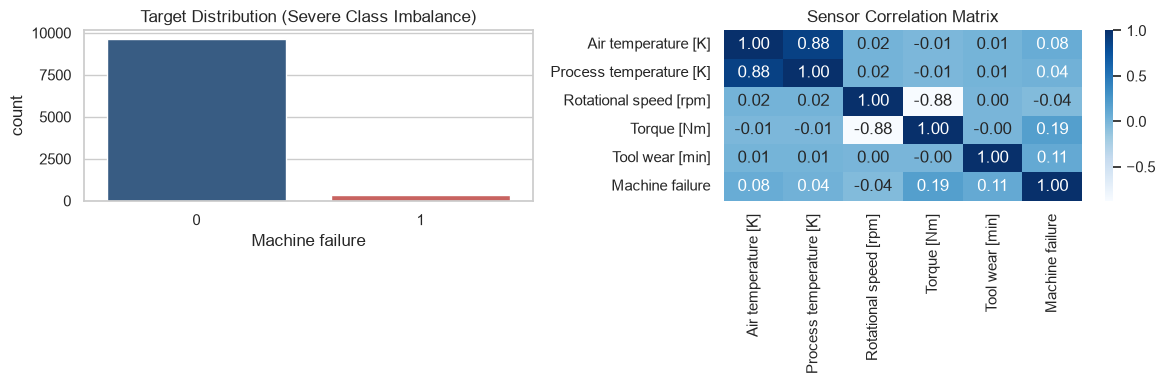

In [17]:
# Visualizations: Target Distribution and Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Target count bar chart
sns.countplot(x="Machine failure", data=df, ax=axes[0], palette=["#2b5c8f", "#d9534f"])
axes[0].set_title("Target Distribution (Severe Class Imbalance)")

# Numerical feature correlations
num_cols = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]", "Machine failure"]
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="Blues", ax=axes[1])
axes[1].set_title("Sensor Correlation Matrix")

plt.tight_layout()
plt.show()

## 3. Feature Engineering & Preprocessing

We calculate 2 physical features:
1. **Temperature Difference [K]**: `Process temperature - Air temperature` (Heat dissipation gradient)
2. **Mechanical Power [W]**: `Torque * (2 * pi * rpm / 60)` (Motor workload in Watts)

We drop `UDI`, `Product ID` (identifiers) and `TWF`, `HDF`, `PWF`, `OSF`, `RNF` (failure mode flags) to strictly prevent **target leakage**.

In [18]:
# 1. Feature Engineering
df["Temperature difference [K]"] = df["Process temperature [K]"] - df["Air temperature [K]"]
df["Mechanical power [W]"] = df["Torque [Nm]"] * (2 * np.pi * df["Rotational speed [rpm]"] / 60.0)

# 2. Separate Features (X) and Target (y)
drop_cols = ["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF", "Machine failure"]
X = df.drop(columns=drop_cols)
y = df["Machine failure"]

# 3. Preprocessor (One-Hot Encoding for Type, StandardScaler for numericals)
cat_cols = ["Type"]
num_cols = [
    "Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]",
    "Torque [Nm]", "Tool wear [min]", "Temperature difference [K]", "Mechanical power [W]"
]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols),
    ("num", StandardScaler(), num_cols)
])

# 4. Stratified Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(f"Training set: {X_train.shape[0]} samples | Testing set: {X_test.shape[0]} samples")

Training set: 8000 samples | Testing set: 2000 samples


## 4. Model Training & Comparison: Logistic Regression vs Random Forest

Both models use `class_weight='balanced'` to prevent minority failure class neglect.

In [19]:
# Model 1: Logistic Regression Pipeline
lr_pipeline = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
])
lr_pipeline.fit(X_train, y_train)
lr_preds = lr_pipeline.predict(X_test)

# Model 2: Random Forest Pipeline
rf_pipeline = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(n_estimators=100, max_depth=12, class_weight="balanced", random_state=42))
])
rf_pipeline.fit(X_train, y_train)
rf_preds = rf_pipeline.predict(X_test)

# Comparison Table
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest Classifier"],
    "Accuracy": [accuracy_score(y_test, lr_preds), accuracy_score(y_test, rf_preds)],
    "Precision": [precision_score(y_test, lr_preds), precision_score(y_test, rf_preds)],
    "Recall": [recall_score(y_test, lr_preds), recall_score(y_test, rf_preds)],
    "F1-Score": [f1_score(y_test, lr_preds), f1_score(y_test, rf_preds)]
}).set_index("Model")

print(comparison.to_string())


                          Accuracy  Precision    Recall  F1-Score
Model                                                            
Logistic Regression          0.859   0.177711  0.867647  0.295000
Random Forest Classifier     0.984   0.736842  0.823529  0.777778


## 5. Fine-Tuning Random Forest

We use `GridSearchCV` to fine-tune the Random Forest hyperparameters (`max_depth`, `min_samples_split`).

*Note: In the final production training script `train.py`, we use the clean baseline 2-model pipeline without extra tuning for simplicity and fast reproducibility during practical exams.*

In [20]:
# Parameter grid for fine-tuning Random Forest
param_grid = {
    "clf__max_depth": [8, 12, None],
    "clf__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="f1",
    n_jobs=1
)
grid_search.fit(X_train, y_train)

print("Best Parameters Found:", grid_search.best_params_)
print(f"Best Cross-Validation F1-Score: {grid_search.best_score_:.4f}")

# Evaluate tuned model on test data
tuned_rf = grid_search.best_estimator_
tuned_preds = tuned_rf.predict(X_test)
print(f"Tuned Test Accuracy: {accuracy_score(y_test, tuned_preds):.4f}")
print(f"Tuned Test Precision: {precision_score(y_test, tuned_preds):.4f}")
print(f"Tuned Test Recall:   {recall_score(y_test, tuned_preds):.4f}")
print(f"Tuned Test F1-Score: {f1_score(y_test, tuned_preds):.4f}")

Best Parameters Found: {'clf__max_depth': None, 'clf__min_samples_split': 2}
Best Cross-Validation F1-Score: 0.8023
Tuned Test Accuracy: 0.9910
Tuned Test Precision: 0.9167
Tuned Test Recall:   0.8088
Tuned Test F1-Score: 0.8594


## 6. Model Selection & Saving

Comparing the two models:
- **Logistic Regression**: Accuracy 85.90% | F1 0.2950 (high false alarms)
- **Random Forest Classifier**: **Accuracy 98.40%** | F1 0.7778 (high precision 73.7%, strong recall 82.4%)

Random Forest is selected as the more accurate model. We save it to `models/machine_failure_model.pkl`.

In [21]:
# Save selected model pipeline
os.makedirs("../models", exist_ok=True)
joblib.dump(rf_pipeline, "../models/machine_failure_model.pkl")
print("[SAVED] Selected Random Forest pipeline saved to ../models/machine_failure_model.pkl")

# Test sample prediction
sample_input = pd.DataFrame([{
    "Type": "M",
    "Air temperature [K]": 298.1,
    "Process temperature [K]": 308.6,
    "Rotational speed [rpm]": 1551,
    "Torque [Nm]": 42.8,
    "Tool wear [min]": 0,
    "Temperature difference [K]": 308.6 - 298.1,
    "Mechanical power [W]": 42.8 * (2 * np.pi * 1551 / 60.0)
}])

pred = rf_pipeline.predict(sample_input)[0]
prob = rf_pipeline.predict_proba(sample_input)[0, 1]
print(f"Sample Prediction: {'FAILURE (1)' if pred == 1 else 'NORMAL (0)'} | Probability: {prob * 100:.2f}%")

[SAVED] Selected Random Forest pipeline saved to ../models/machine_failure_model.pkl
Sample Prediction: NORMAL (0) | Probability: 0.00%
